In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

cbc = pd.read_csv("LSDS-7_Complete_Blood_Count_CBC.upload_SUBMITTED.csv")
cmp = pd.read_csv("LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv")

print("CBC shape:", cbc.shape)
print("\n")
print("CMP shape:", cmp.shape)

display(cbc.head())
print("\n")
display(cmp.head())

CBC shape: (553, 9)


CMP shape: (28, 58)


,ANALYTE,VALUE,RANGE_MIN,RANGE_MAX,UNITS,TEST_TYPE,SUBJECT_ID,SEX,TEST_DATE
0,WHITE BLOOD CELL COUNT,5.40,3.8,10.8,Thousand/uL,CBC,C001,M,L-92
1,RED BLOOD CELL COUNT,4.58,4.2,5.8,Million/uL,CBC,C001,M,L-92
2,HEMOGLOBIN,14.10,13.2,17.1,g/dL,CBC,C001,M,L-92
3,HEMATOCRIT,42.50,38.5,50.0,%,CBC,C001,M,L-92
4,MCV,92.80,80.0,100.0,fL,CBC,C001,M,L-92


,Sample Name,albumin_value_gram_per_deciliter,albumin_range_min_gram_per_deciliter,albumin_range_max_gram_per_deciliter,albumin_to_globulin_ratio_value,albumin_to_globulin_ratio_range_min,albumin_to_globulin_ratio_range_max,alkaline_phosphatase_value_units_per_liter,alkaline_phosphatase_range_min_units_per_liter,alkaline_phosphatase_range_max_units_per_liter,...,potassium_range_max_millimol_per_liter,total_protein_value_gram_per_deciliter,total_protein_range_min_gram_per_deciliter,total_protein_range_max_gram_per_deciliter,sodium_value_millimol_per_liter,sodium_range_min_millimol_per_liter,sodium_range_max_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter,urea_nitrogen_bun_range_min_milligram_per_deciliter,urea_nitrogen_bun_range_max_milligram_per_deciliter
0,C001_serum_L-3,4.9,3.6,5.1,2.0,1,2.5,45,36,130,...,5.3,7.4,6.1,8.1,142,135,146,20,7,25
1,C001_serum_L-44,5.0,3.6,5.1,1.9,1,2.5,46,36,130,...,5.3,7.7,6.1,8.1,139,135,146,19,7,25
2,C001_serum_L-92,5.0,3.6,5.1,2.2,1,2.5,51,36,130,...,5.3,7.3,6.1,8.1,141,135,146,25,7,25
3,C001_serum_R+1,4.9,3.6,5.1,1.9,1,2.5,52,36,130,...,5.3,7.5,6.1,8.1,138,135,146,18,7,25
4,C001_serum_R+194,4.6,3.6,5.1,1.9,1,2.5,50,36,130,...,5.3,7.0,6.1,8.1,137,135,146,28,7,25


In [ ]:
df1 = cbc.copy()

In [ ]:
df2 = cmp.copy()

In [ ]:
df1.head()

,ANALYTE,VALUE,RANGE_MIN,RANGE_MAX,UNITS,TEST_TYPE,SUBJECT_ID,SEX,TEST_DATE
0,WHITE BLOOD CELL COUNT,5.40,3.8,10.8,Thousand/uL,CBC,C001,M,L-92
1,RED BLOOD CELL COUNT,4.58,4.2,5.8,Million/uL,CBC,C001,M,L-92
2,HEMOGLOBIN,14.10,13.2,17.1,g/dL,CBC,C001,M,L-92
3,HEMATOCRIT,42.50,38.5,50.0,%,CBC,C001,M,L-92
4,MCV,92.80,80.0,100.0,fL,CBC,C001,M,L-92


In [ ]:
print("------Complete Blood Count Basic inspection: ------")

print("shapes in cbc : ",df1.shape)
print("\n Columns names : \n",df1.columns.tolist())
print("\nData types and non-null counts:")
display(df1.info())

print("\n Missing value per column: \n")
print(df1.isnull().sum())


print("\n Duplicated counts :",df1.duplicated().sum())

------Complete Blood Count Basic inspection: ------
shapes in cbc :  (553, 9)

 Columns names : 
 ['ANALYTE', 'VALUE', 'RANGE_MIN', 'RANGE_MAX', 'UNITS', 'TEST_TYPE', 'SUBJECT_ID', 'SEX', 'TEST_DATE']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 553 entries, 0 to 552
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ANALYTE     553 non-null    object 
 1   VALUE       553 non-null    float64
 2   RANGE_MIN   553 non-null    float64
 3   RANGE_MAX   553 non-null    float64
 4   UNITS       553 non-null    object 
 5   TEST_TYPE   553 non-null    object 
 6   SUBJECT_ID  553 non-null    object 
 7   SEX         553 non-null    object 
 8   TEST_DATE   553 non-null    object 
dtypes: float64(3), object(6)
memory usage: 39.0+ KB


None


 Missing value per column: 

ANALYTE       0
VALUE         0
RANGE_MIN     0
RANGE_MAX     0
UNITS         0
TEST_TYPE     0
SUBJECT_ID    0
SEX           0
TEST_DATE     0
dtype: int64

 Duplicated counts : 0


In [ ]:
print("Unique participants:")
print(df1["SUBJECT_ID"].unique())

print("\nTime points:")
print(df1["TEST_DATE"].value_counts())

print("\nNumber of unique analytes:")
print(df1["ANALYTE"].nunique())

print("\nAnalytes available:")
print(sorted(df1["ANALYTE"].unique()))

Unique participants:
['C001' 'C002' 'C004' 'C003']

Time points:
TEST_DATE
R+45     80
R+82     80
L-44     79
R+1      79
L-3      79
R+194    79
L-92     77
Name: count, dtype: int64

Number of unique analytes:
23

Analytes available:
['ABSOLUTE BASOPHILS', 'ABSOLUTE EOSINOPHILS', 'ABSOLUTE LYMPHOCYTES', 'ABSOLUTE MONOCYTES', 'ABSOLUTE NEUTROPHILS', 'BASOPHILS', 'EOSINOPHILS', 'HEMATOCRIT', 'HEMATOCRIT (FEMALE)', 'HEMOGLOBIN', 'HEMOGLOBIN (FEMALE)', 'LYMPHOCYTES', 'MCH', 'MCHC', 'MCV', 'MONOCYTES', 'MPV', 'NEUTROPHILS', 'PLATELET COUNT', 'RDW', 'RED BLOOD CELL COUNT', 'RED BLOOD CELL COUNT (FEMALE)', 'WHITE BLOOD CELL COUNT']


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 553 entries, 0 to 552
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ANALYTE     553 non-null    object 
 1   VALUE       553 non-null    float64
 2   RANGE_MIN   553 non-null    float64
 3   RANGE_MAX   553 non-null    float64
 4   UNITS       553 non-null    object 
 5   TEST_TYPE   553 non-null    object 
 6   SUBJECT_ID  553 non-null    object 
 7   SEX         553 non-null    object 
 8   TEST_DATE   553 non-null    object 
dtypes: float64(3), object(6)
memory usage: 39.0+ KB


In [ ]:
# Count observations per participant and analyte
coverage = (
    df1.groupby(["SUBJECT_ID", "ANALYTE"])["VALUE"]
       .count()
       .unstack(fill_value=0)
)

display(coverage)

ANALYTE,ABSOLUTE BASOPHILS,ABSOLUTE EOSINOPHILS,ABSOLUTE LYMPHOCYTES,ABSOLUTE MONOCYTES,ABSOLUTE NEUTROPHILS,BASOPHILS,EOSINOPHILS,HEMATOCRIT,HEMATOCRIT (FEMALE),HEMOGLOBIN,...,MCHC,MCV,MONOCYTES,MPV,NEUTROPHILS,PLATELET COUNT,RDW,RED BLOOD CELL COUNT,RED BLOOD CELL COUNT (FEMALE),WHITE BLOOD CELL COUNT
SUBJECT_ID,,,,,,,,,,,,,,,,,,,,,
C001,7,7,7,7,7,7,7,7,0,7,...,7,7,7,7,7,7,7,7,0,7
C002,7,7,7,7,7,7,7,7,0,7,...,3,6,7,7,7,7,7,7,0,7
C003,7,7,7,7,7,7,7,6,1,6,...,7,7,7,7,7,7,7,6,1,7
C004,7,7,7,7,7,7,7,7,0,7,...,7,7,7,7,7,7,7,7,0,7


In [ ]:
df1.groupby("ANALYTE")["VALUE"].describe()

,count,mean,std,min,25%,50%,75%,max
ANALYTE,,,,,,,,
ABSOLUTE BASOPHILS,28.0,58.928571,25.191016,19.00,45.000,50.50,71.750,125.00
ABSOLUTE EOSINOPHILS,28.0,211.214286,103.151581,88.00,157.750,190.50,258.250,614.00
ABSOLUTE LYMPHOCYTES,28.0,2414.821429,982.981973,1540.00,1918.250,2163.00,2646.000,6826.00
ABSOLUTE MONOCYTES,28.0,666.071429,341.168138,302.00,443.250,588.50,841.500,1997.00
ABSOLUTE NEUTROPHILS,28.0,3640.967857,1349.241691,10.10,2846.000,3658.50,4402.750,6408.00
BASOPHILS,28.0,0.821429,0.321290,0.30,0.575,0.80,1.025,1.40
EOSINOPHILS,28.0,2.892857,1.059675,0.90,2.075,2.75,3.700,4.80
HEMATOCRIT,27.0,43.074074,4.471585,34.70,40.550,43.30,46.800,50.00
HEMATOCRIT (FEMALE),1.0,41.400000,NaN,41.40,41.400,41.40,41.400,41.40


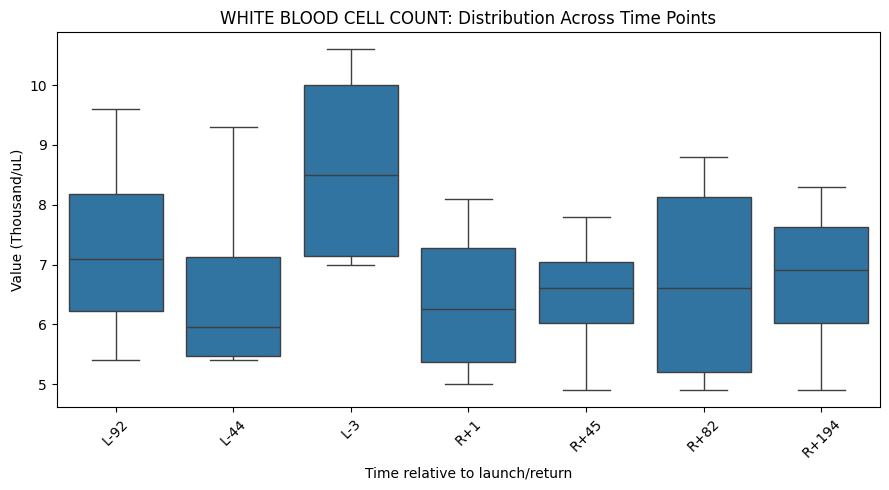

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

analyte_name = "WHITE BLOOD CELL COUNT"

subset = df1[df1["ANALYTE"] == analyte_name]

plt.figure(figsize=(9, 5))
sns.boxplot(data=subset, x="TEST_DATE", y="VALUE",
            order=["L-92", "L-44", "L-3",
                   "R+1", "R+45", "R+82", "R+194"])

plt.title(f"{analyte_name}: Distribution Across Time Points")
plt.xlabel("Time relative to launch/return")
plt.ylabel(f"Value ({subset['UNITS'].iloc[0]})")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

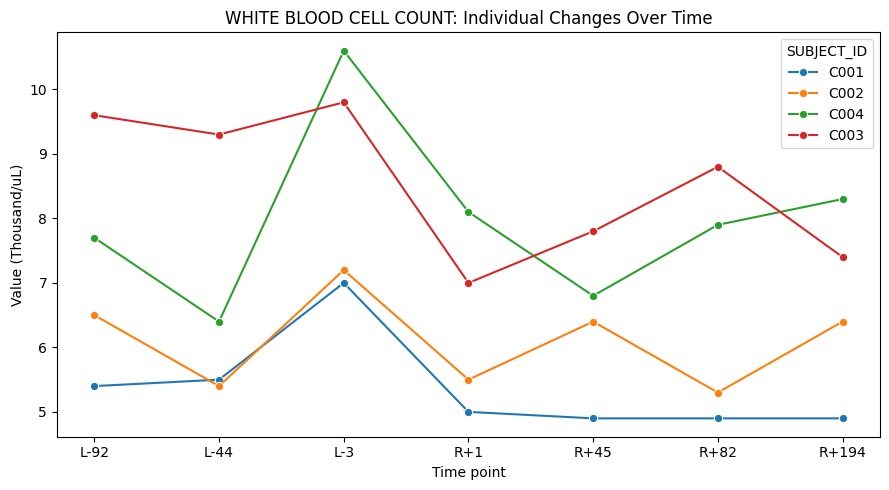

In [ ]:
plt.figure(figsize=(9, 5))

# Using sns.lineplot with 'hue' to color-code each individual subject
sns.lineplot(
    data=subset,
    x="TEST_DATE",
    y="VALUE",
    hue="SUBJECT_ID",
    marker="o"
)

plt.title(f"{analyte_name}: Individual Changes Over Time")
plt.xlabel("Time point")
plt.ylabel(f"Value (Thousand/uL)")
plt.tight_layout()
plt.show()

In [ ]:
# Find the minimum and maximum value for each participant
summary = (
    subset.groupby("SUBJECT_ID")
    .agg(
        min_value=("VALUE", "min"),
        max_value=("VALUE", "max"),
        min_time=("VALUE", lambda s: subset.loc[s.idxmin(), "TEST_DATE"]),
        max_time=("VALUE", lambda s: subset.loc[s.idxmax(), "TEST_DATE"])
    )
)

display(summary)

,min_value,max_value,min_time,max_time
SUBJECT_ID,,,,
C001,4.9,7.0,R+45,L-3
C002,5.3,7.2,R+82,L-3
C003,7.0,9.8,R+1,L-3
C004,6.4,10.6,L-44,L-3


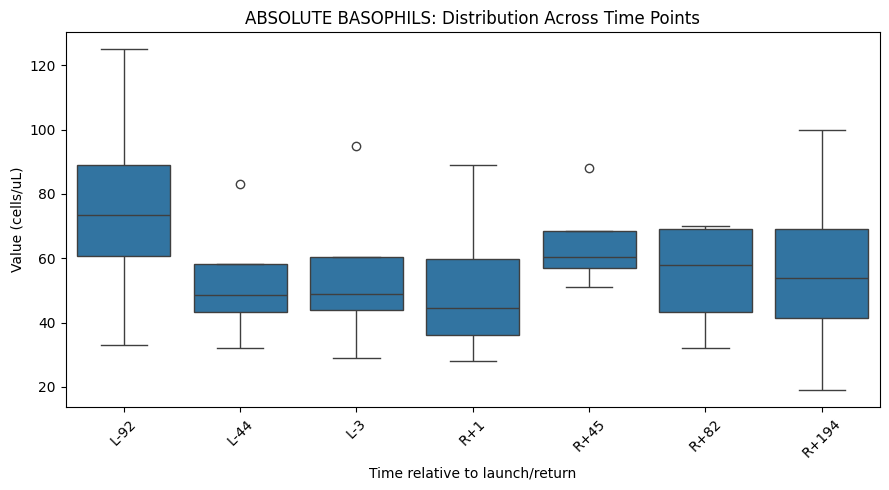

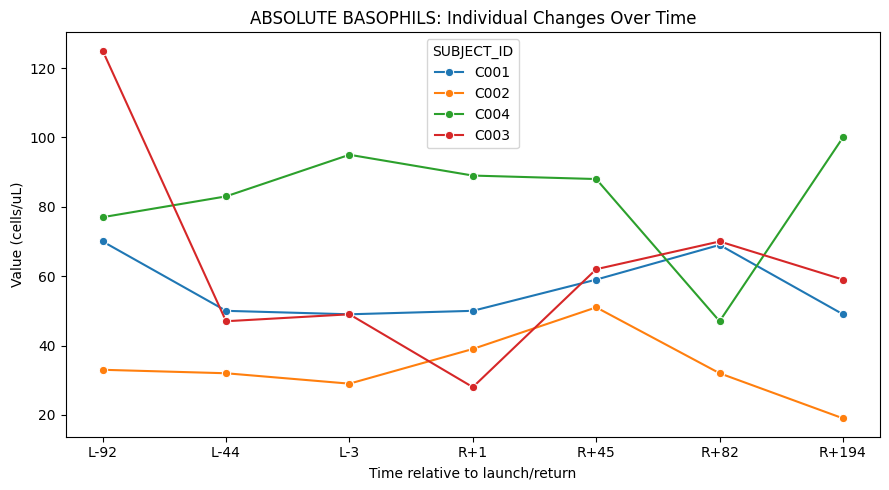

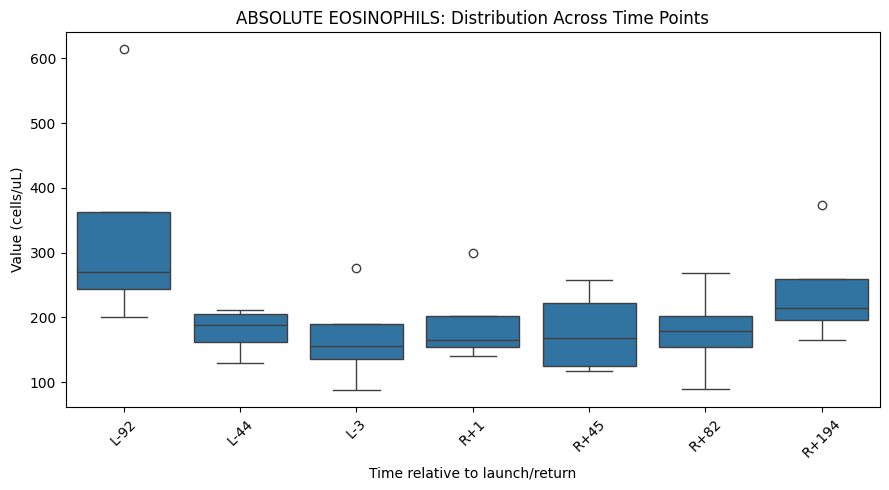

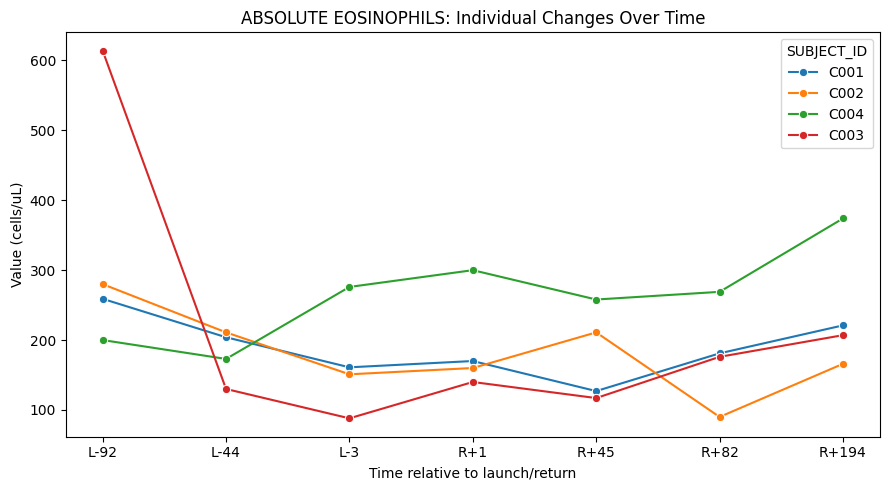

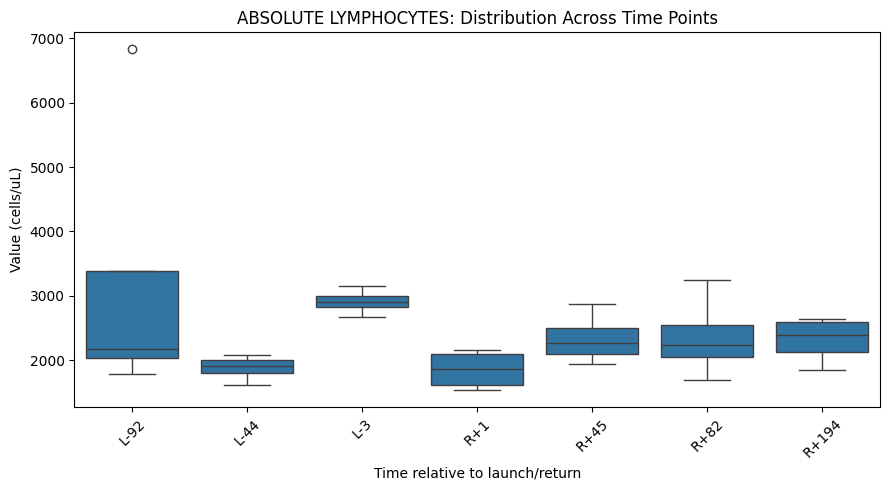

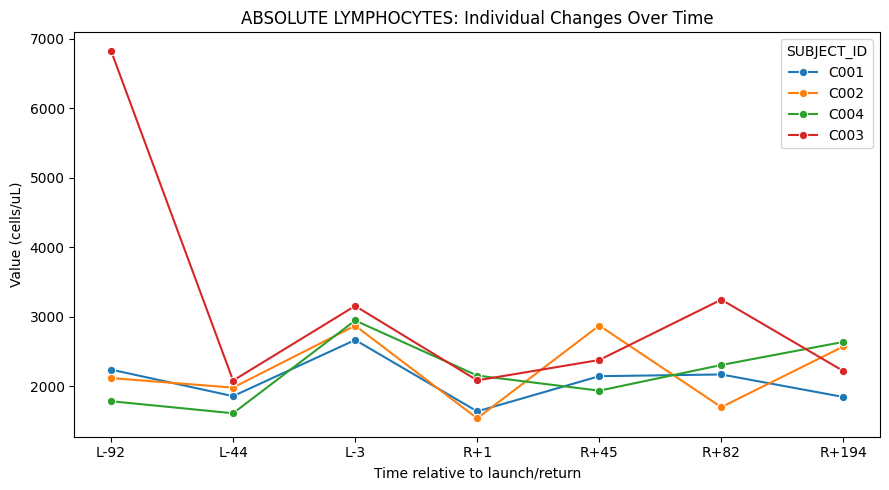

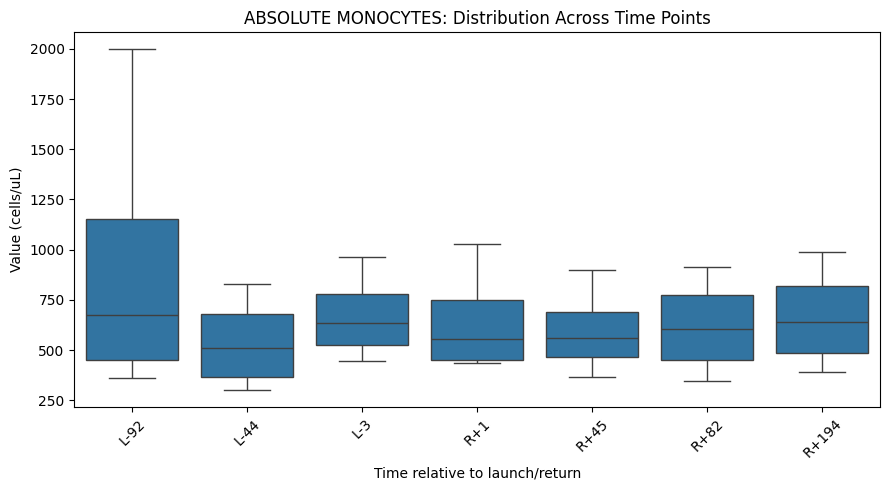

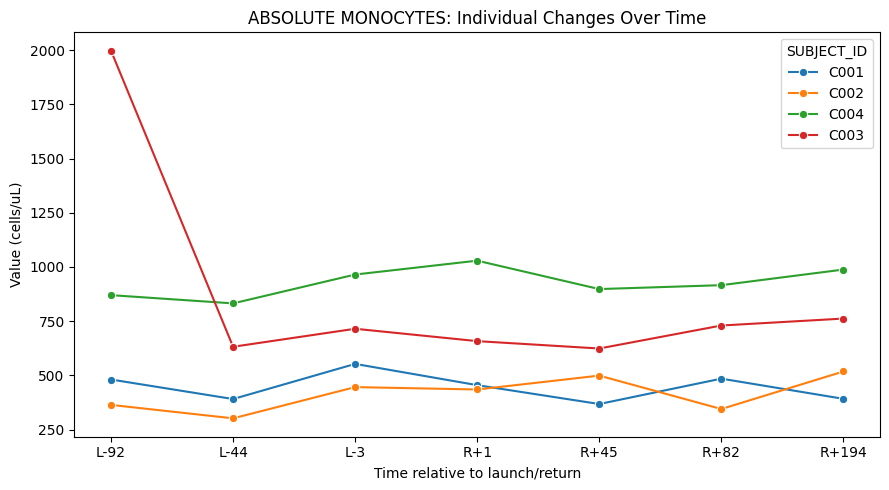

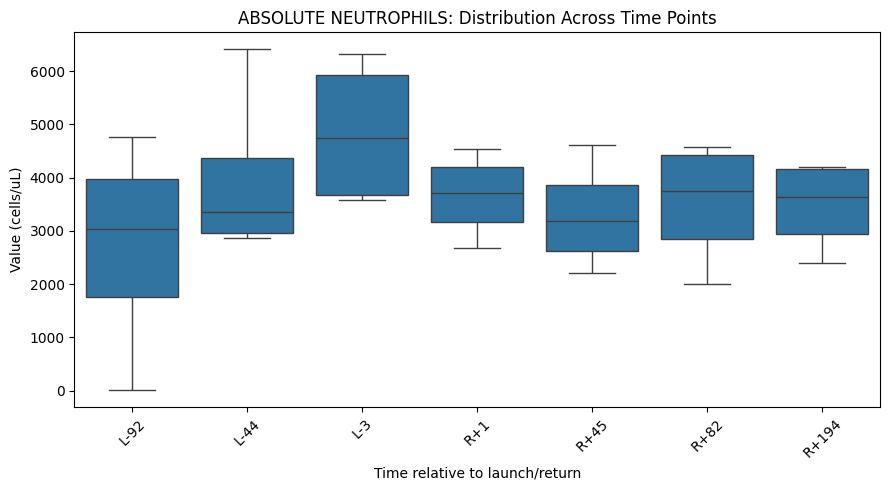

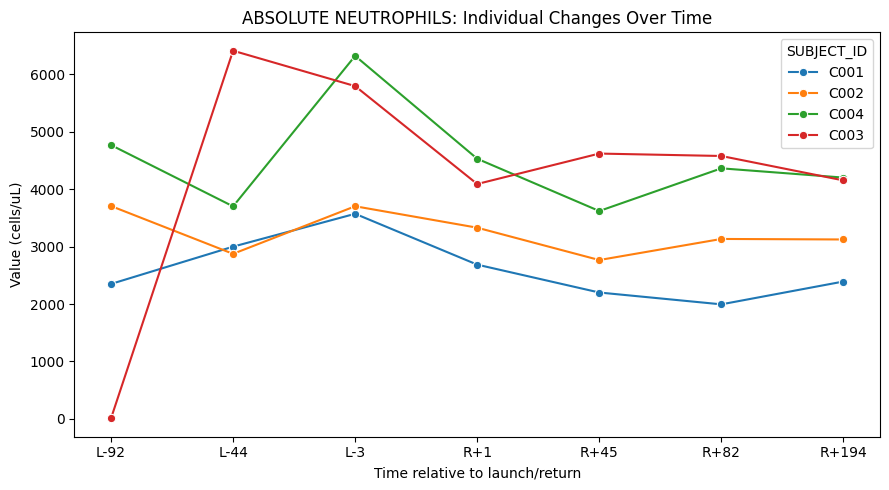

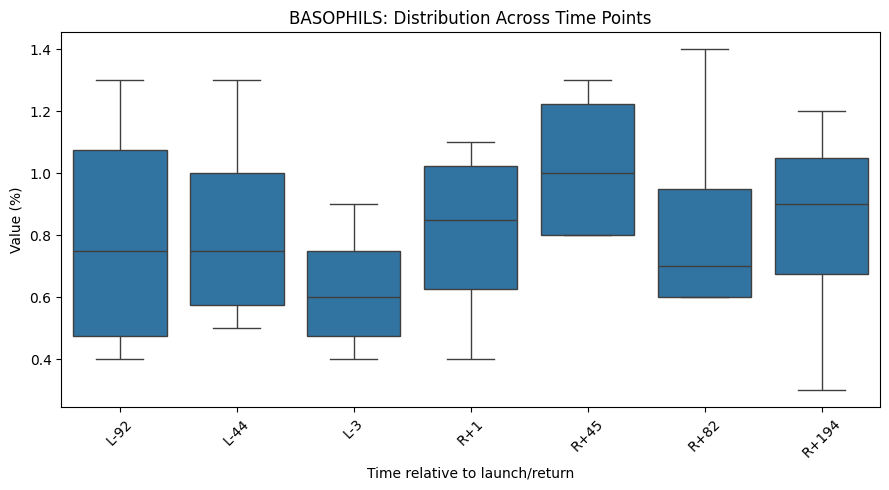

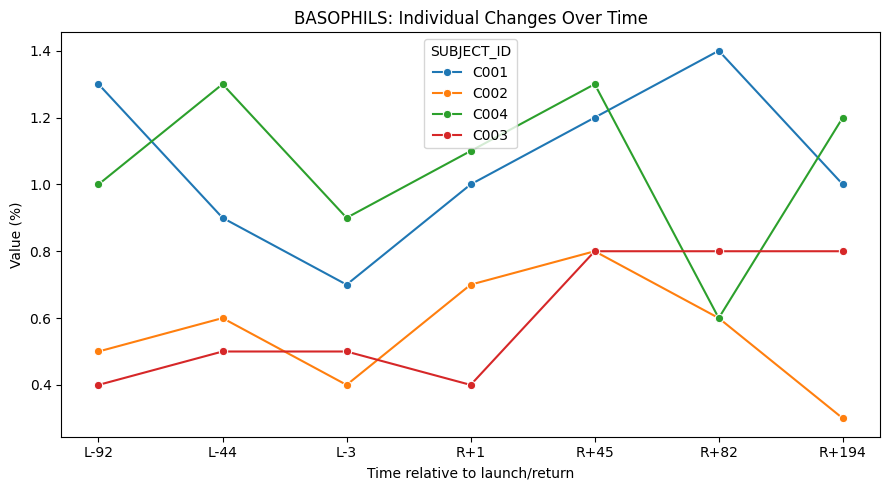

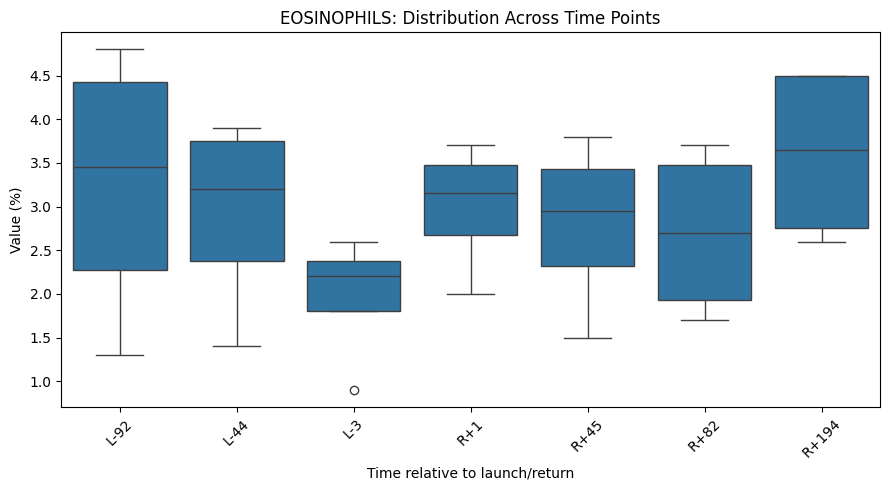

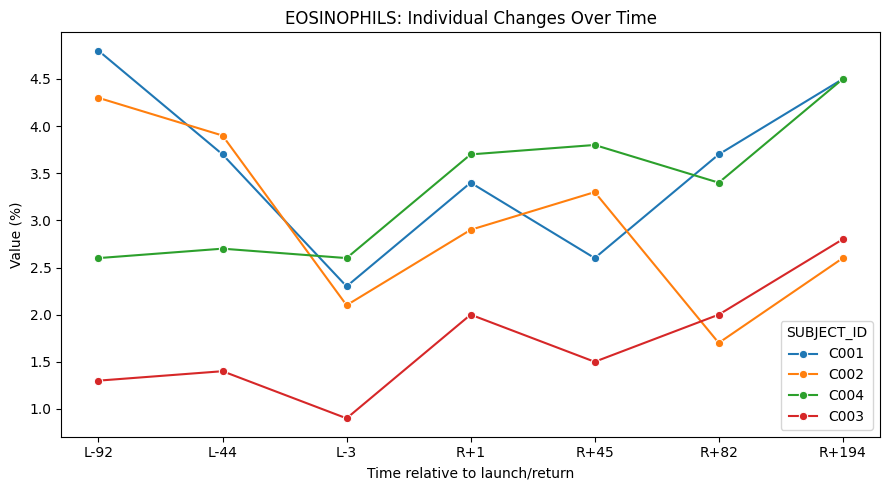

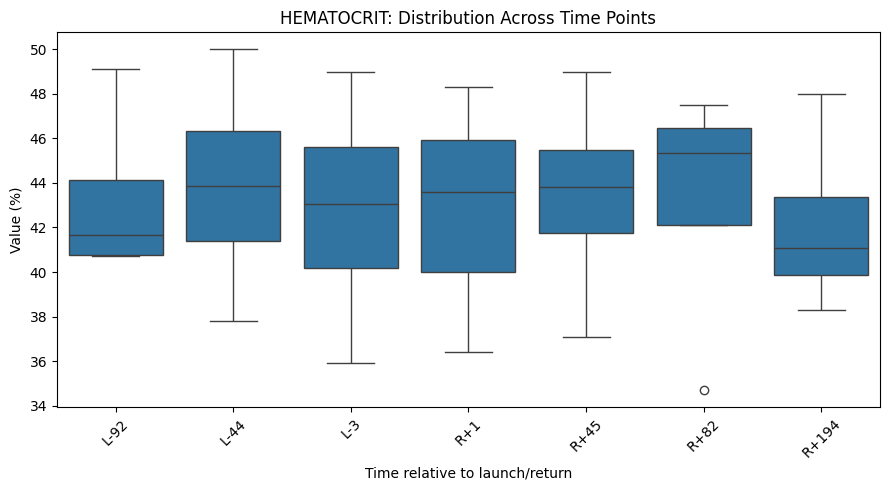

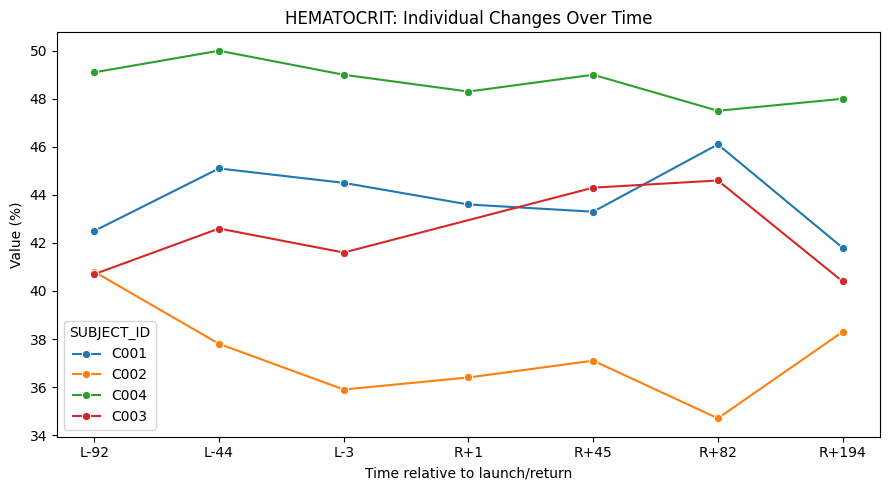

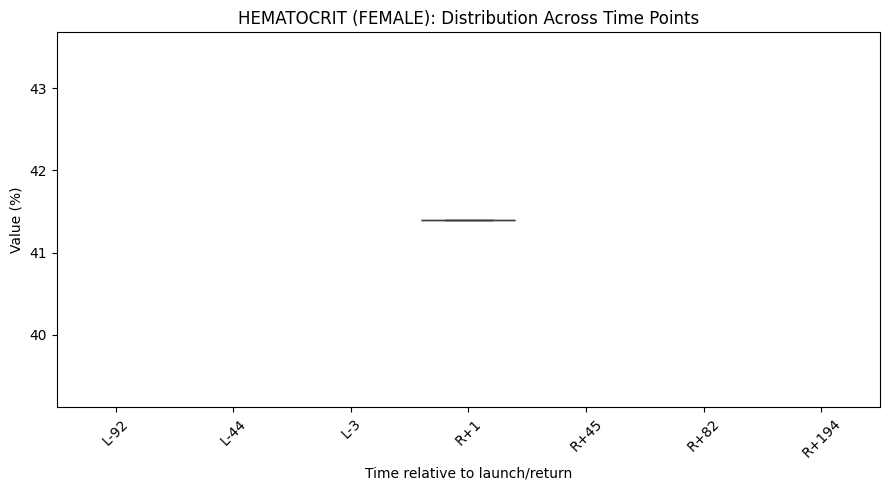

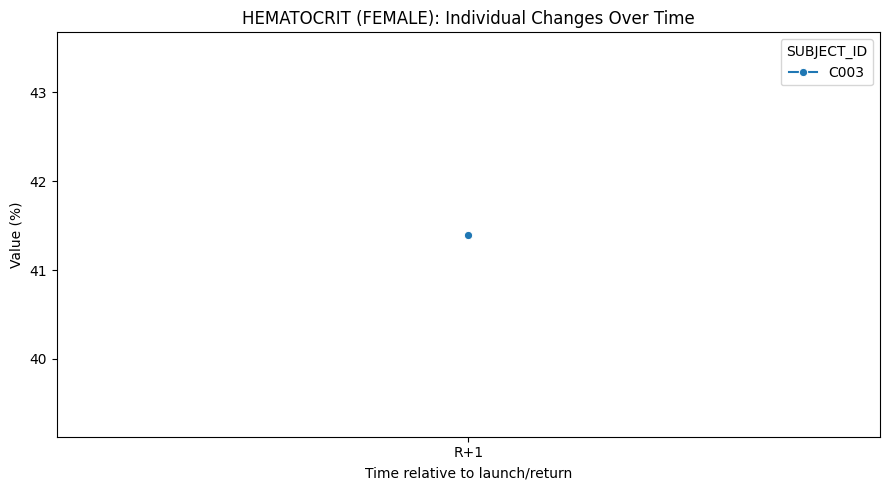

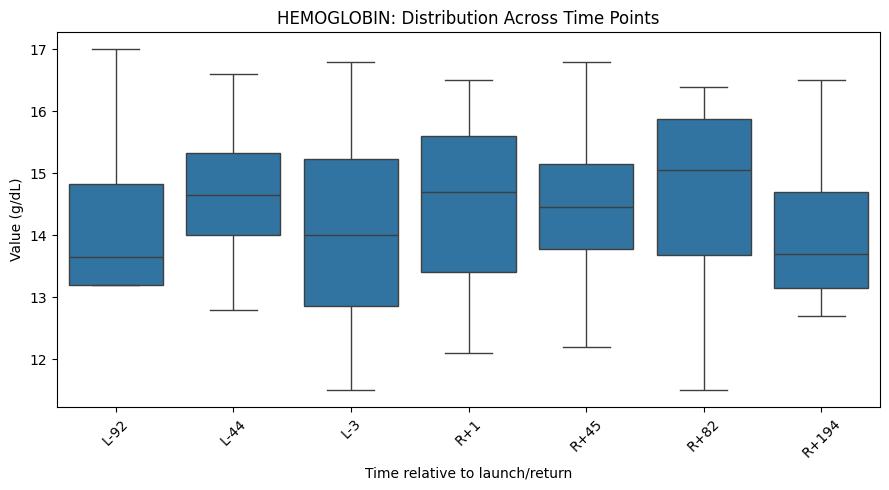

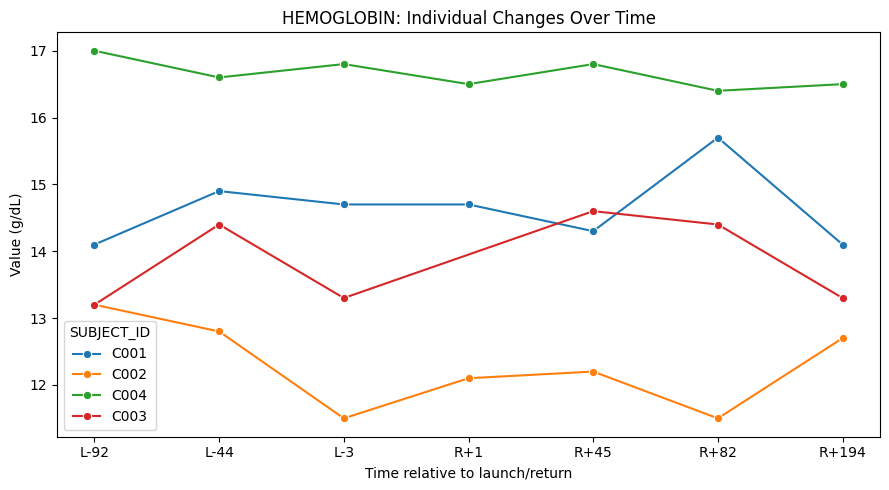

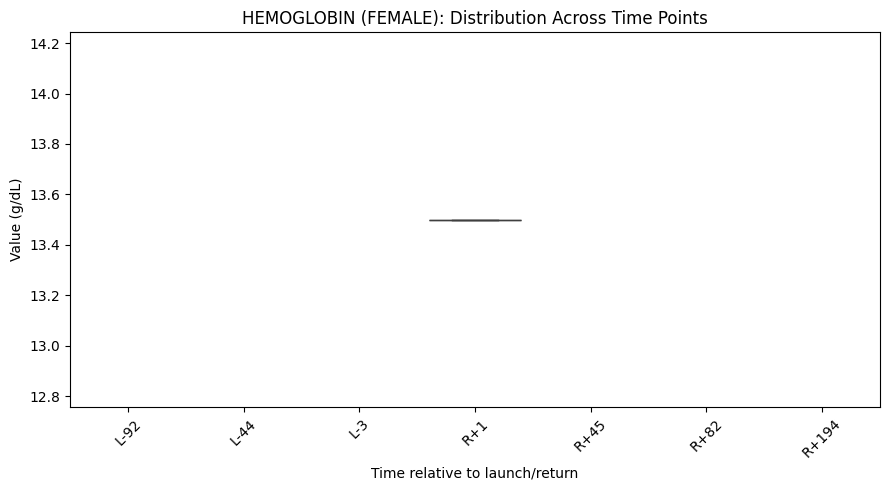

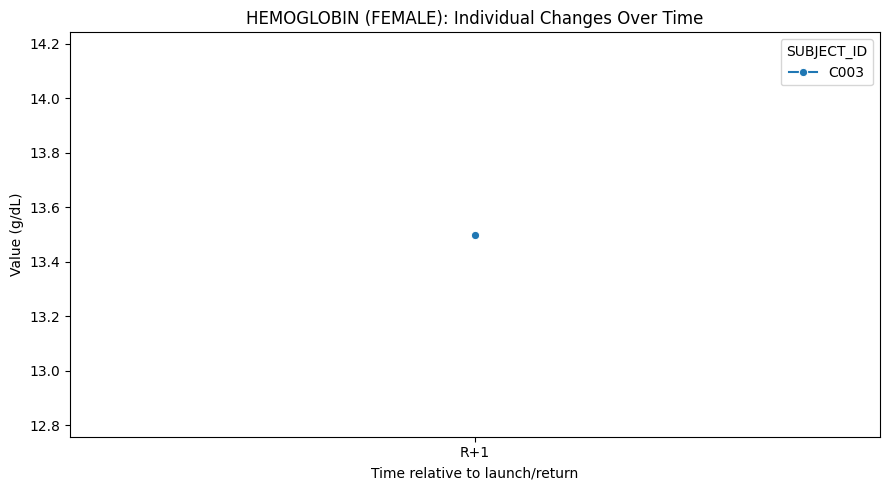

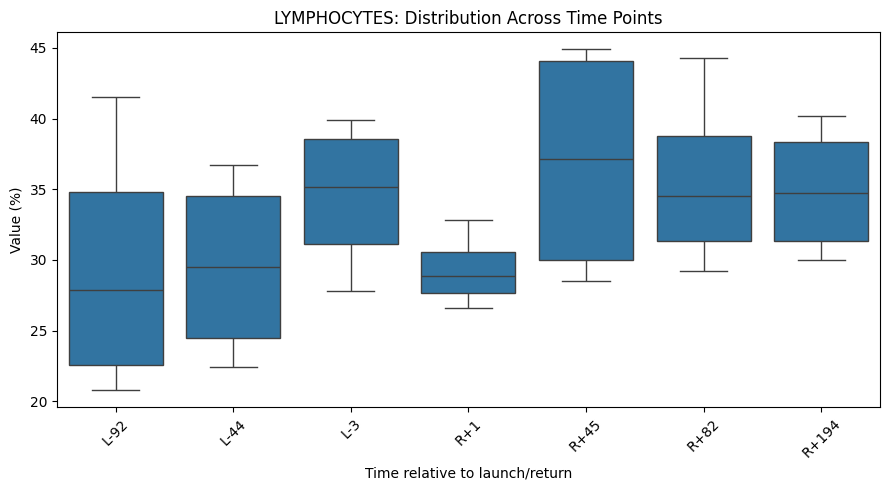

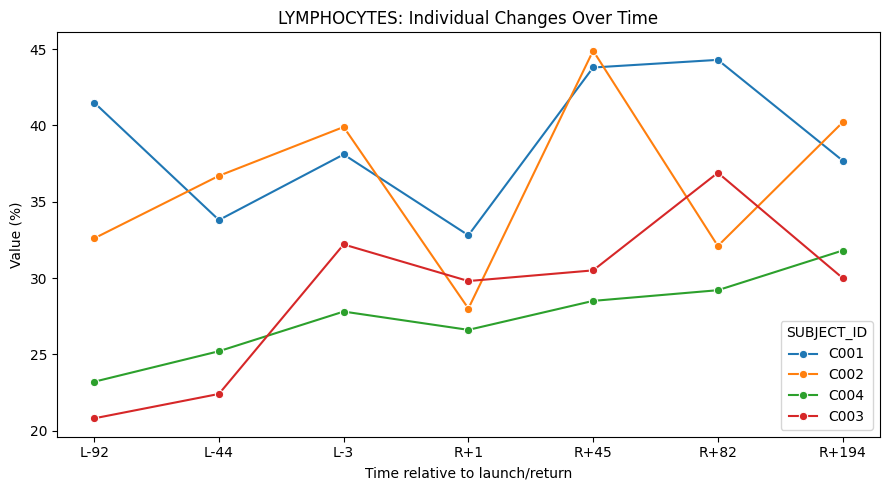

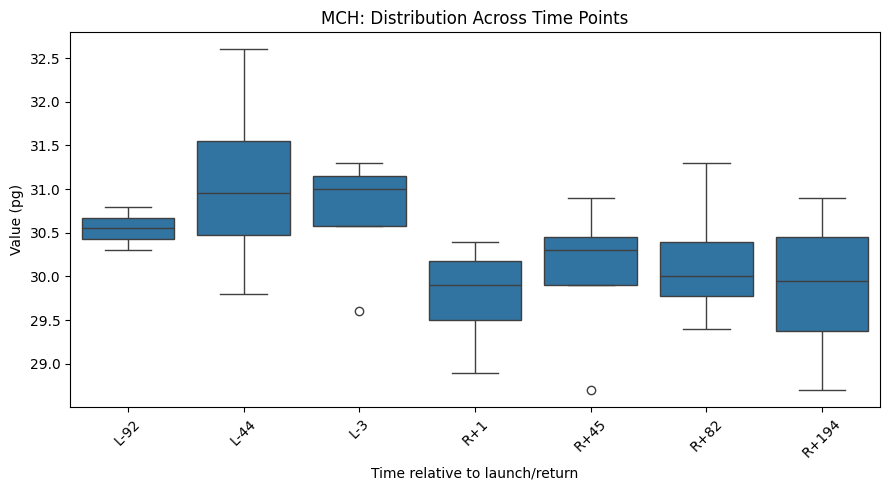

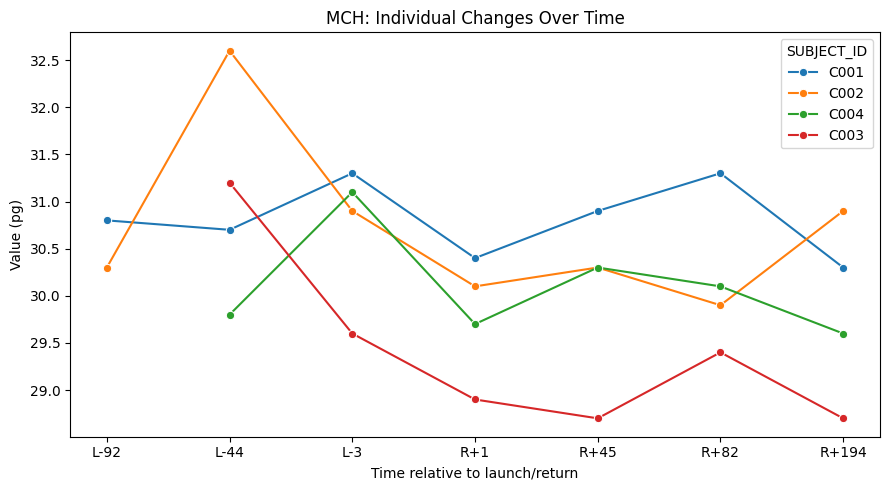

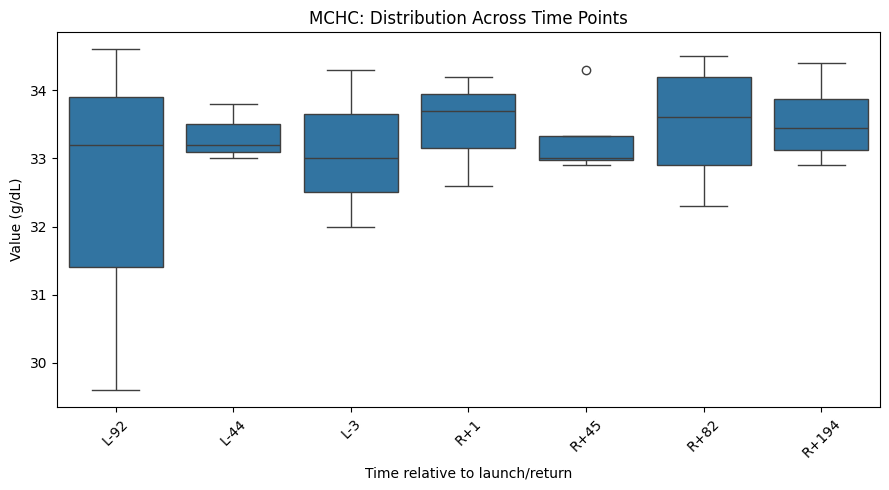

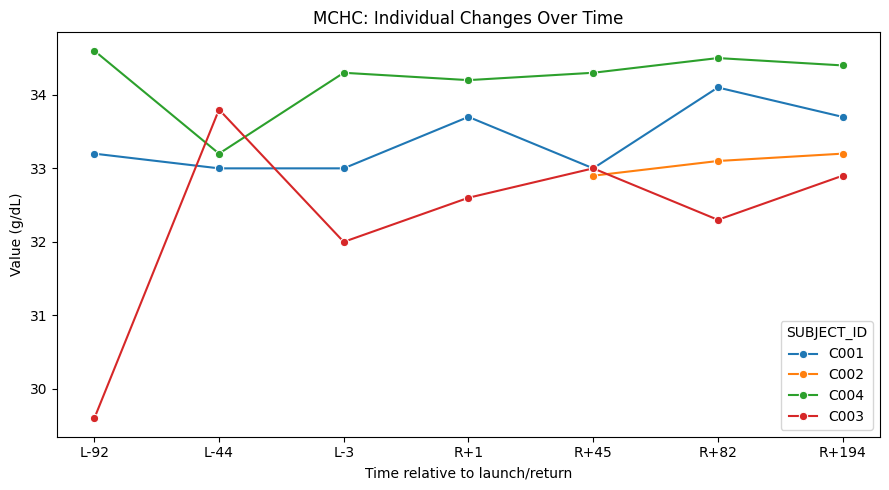

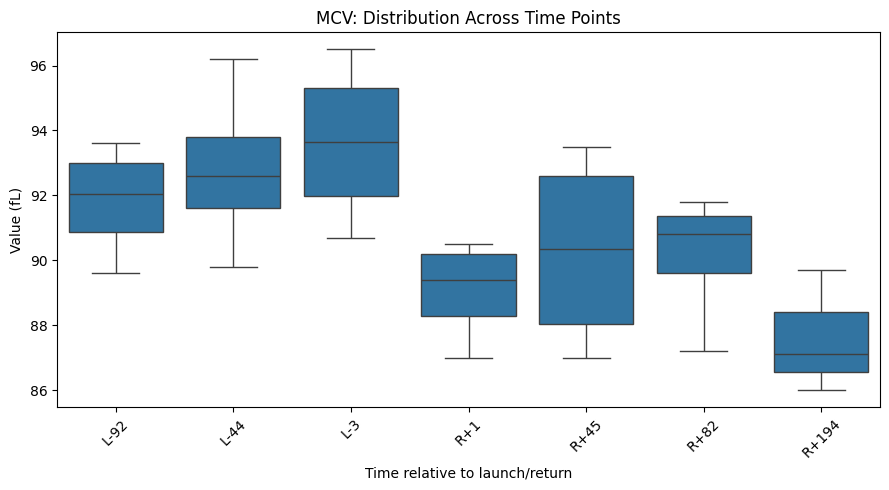

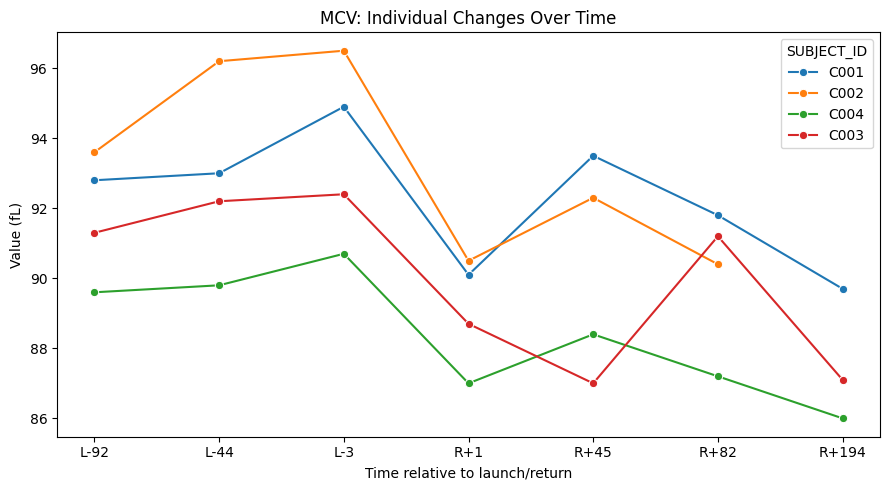

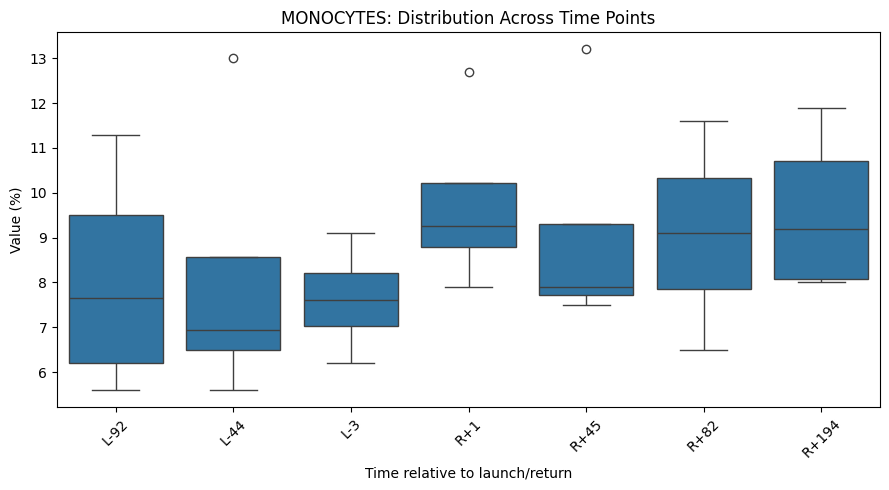

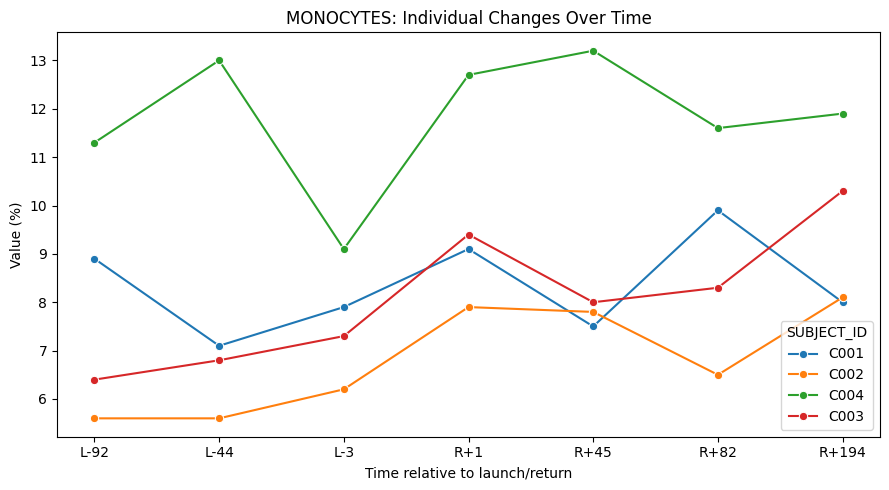

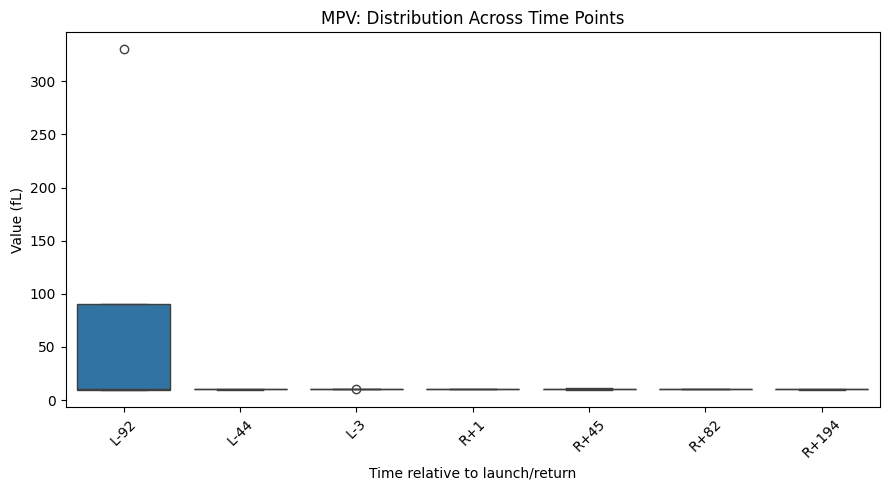

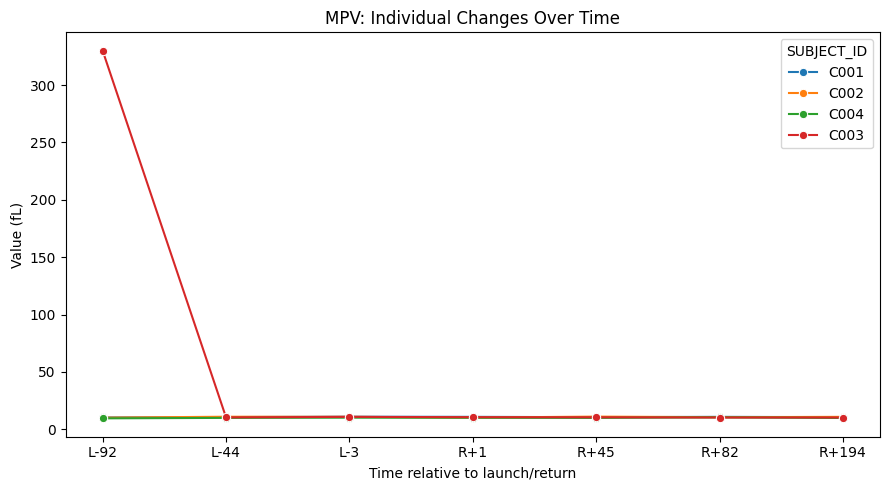

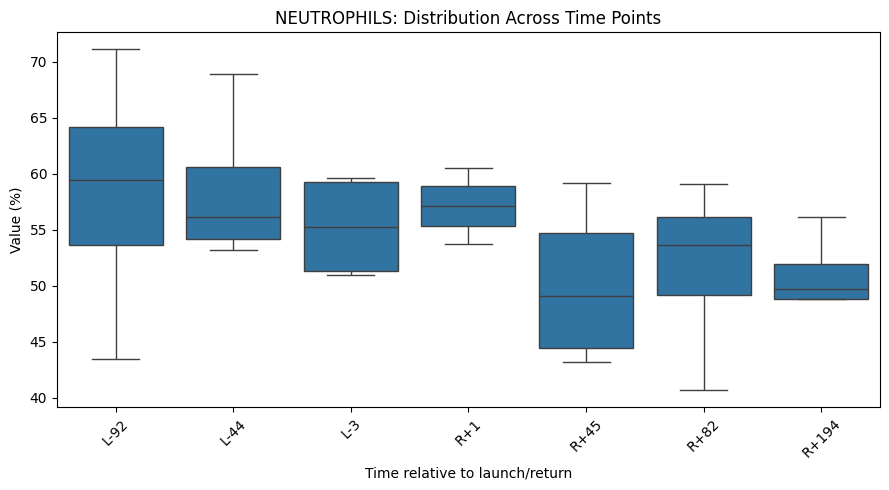

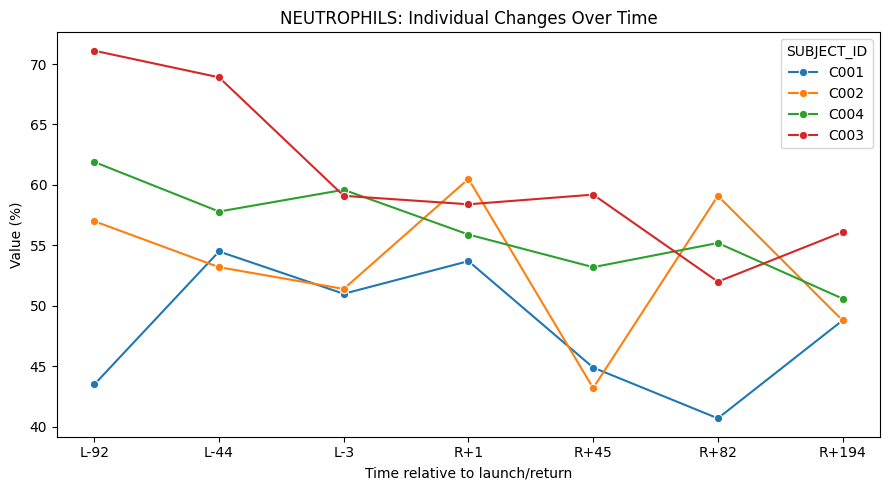

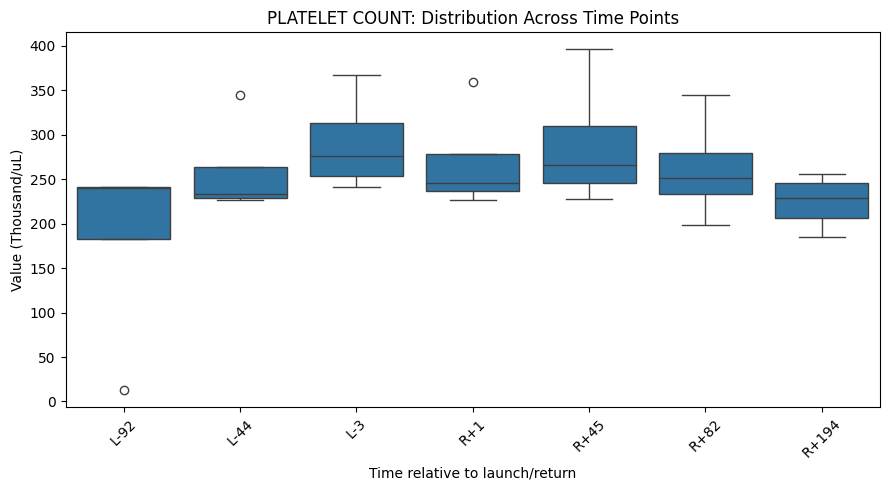

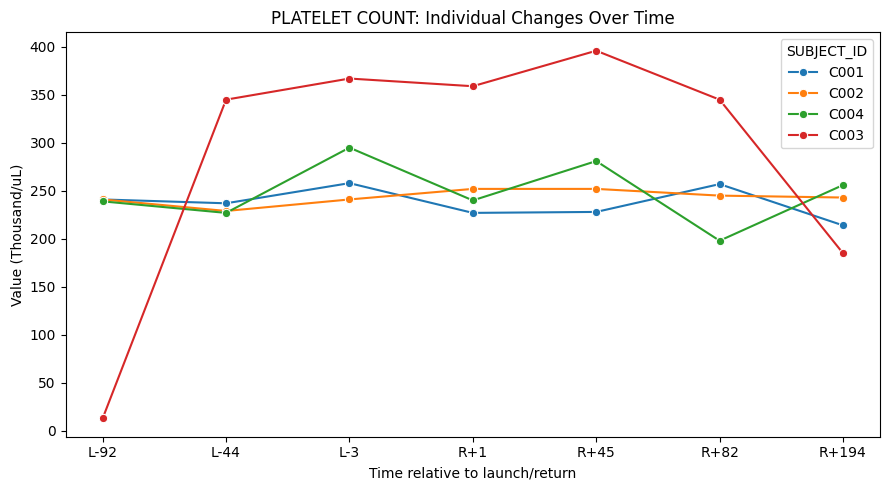

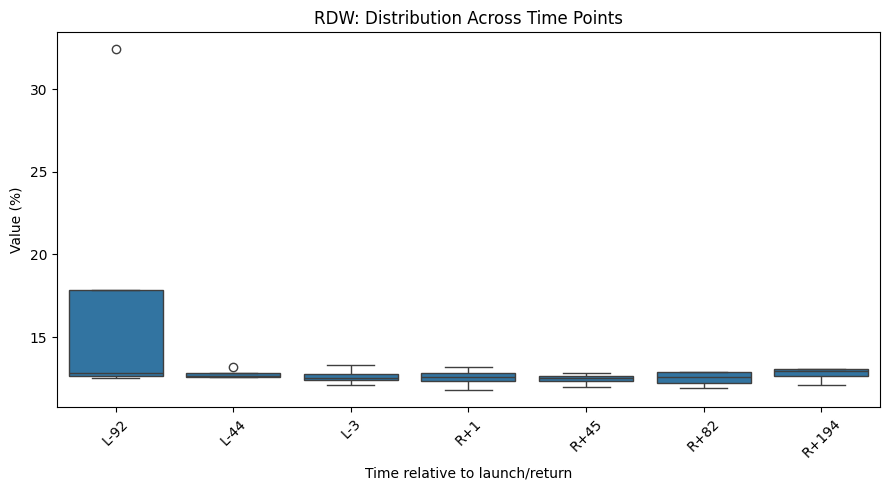

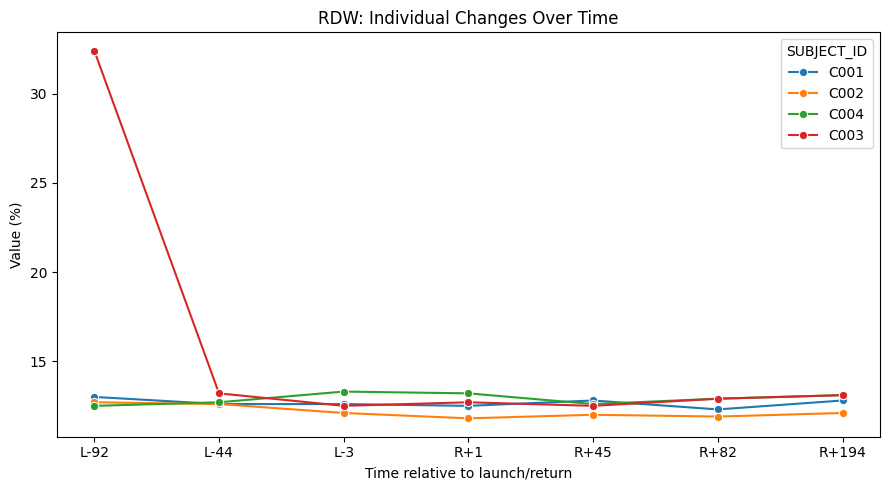

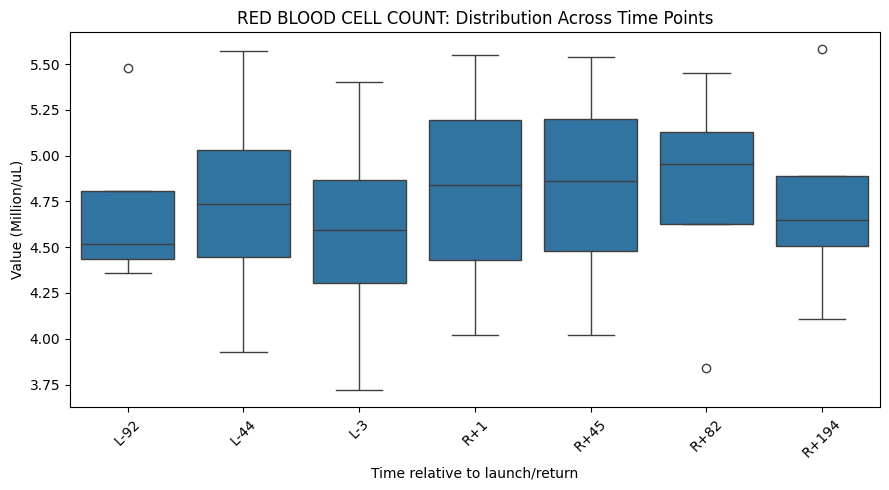

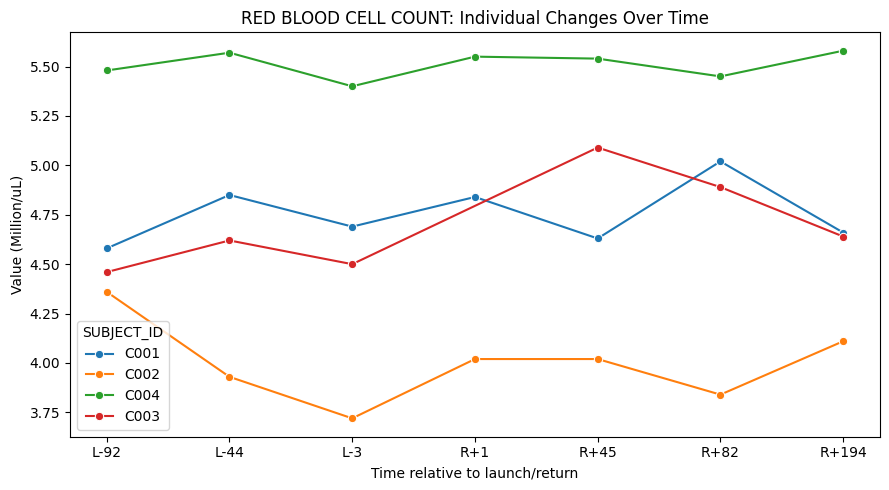

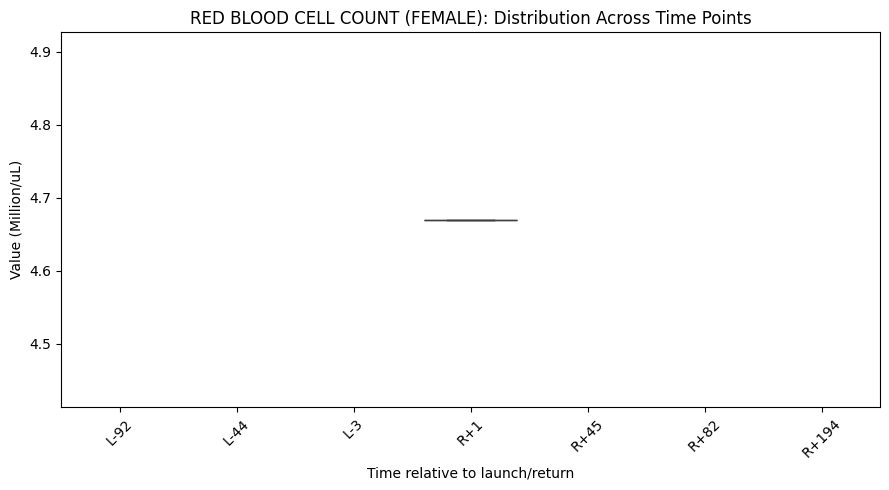

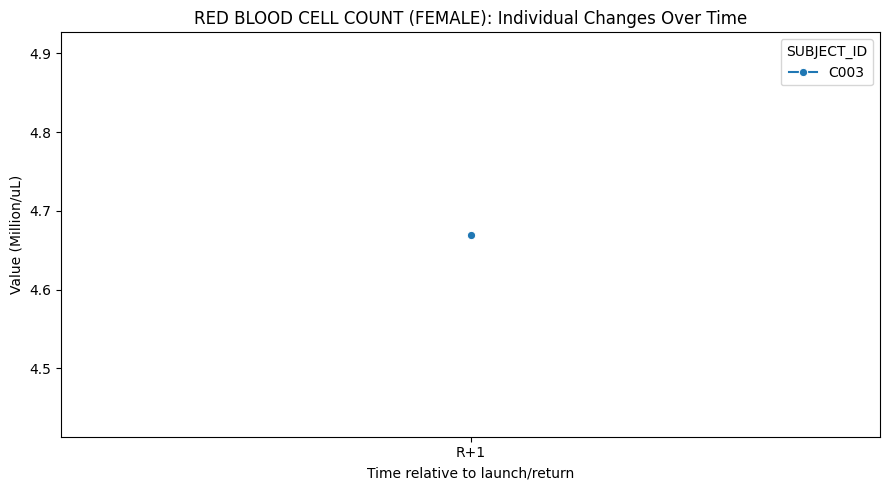

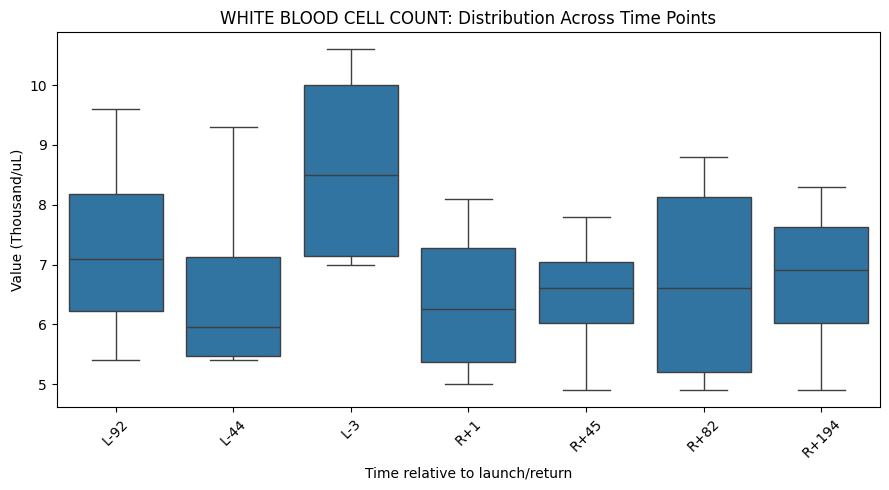

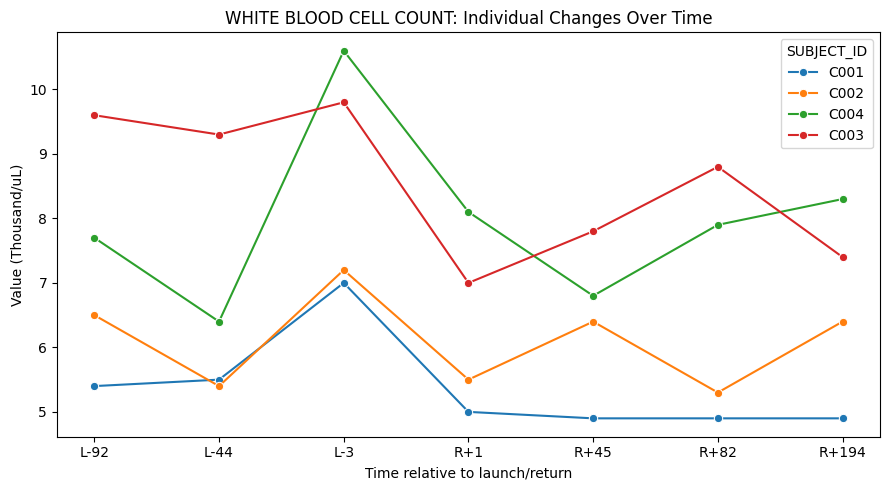

In [ ]:
time_order = [
    "L-92", "L-44", "L-3",
    "R+1", "R+45", "R+82", "R+194"
]

for analyte in sorted(df1["ANALYTE"].unique()):

    subset = df1[df1["ANALYTE"] == analyte].copy()

    subset["TEST_DATE"] = pd.Categorical(
        subset["TEST_DATE"],
        categories=time_order,
        ordered=True
    )

    # Boxplot
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=subset,
        x="TEST_DATE",
        y="VALUE",
        order=time_order
    )
    plt.title(f"{analyte}: Distribution Across Time Points")
    plt.xlabel("Time relative to launch/return")
    plt.ylabel(f"Value ({subset['UNITS'].iloc[0]})")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Individual line plot
    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=subset,
        x="TEST_DATE",
        y="VALUE",
        hue="SUBJECT_ID",
        marker="o",
        estimator=None,
        sort=True
    )
    plt.title(f"{analyte}: Individual Changes Over Time")
    plt.xlabel("Time relative to launch/return")
    plt.ylabel(f"Value ({subset['UNITS'].iloc[0]})")
    plt.tight_layout()
    plt.show()

In [ ]:
for analyte in sorted(df1['ANALYTE'].unique()):
  subset = df1[df1['ANALYTE'] == analyte]
  summary = (
    subset.groupby("SUBJECT_ID")
    .agg(
        min_value=("VALUE", "min"),
        max_value=("VALUE", "max"),
        min_time=("VALUE", lambda s: subset.loc[s.idxmin(), "TEST_DATE"]),
        max_time=("VALUE", lambda s: subset.loc[s.idxmax(), "TEST_DATE"])
    )
  )
  print(analyte)
  display(summary)
  print("\n")

ABSOLUTE BASOPHILS


,min_value,max_value,min_time,max_time
SUBJECT_ID,,,,
C001,49.0,70.0,L-3,L-92
C002,19.0,51.0,R+194,R+45
C003,28.0,125.0,R+1,L-92
C004,47.0,100.0,R+82,R+194




ABSOLUTE EOSINOPHILS


,min_value,max_value,min_time,max_time
SUBJECT_ID,,,,
C001,127.0,259.0,R+45,L-92
C002,90.0,280.0,R+82,L-92
C003,88.0,614.0,L-3,L-92
C004,173.0,374.0,L-44,R+194




ABSOLUTE LYMPHOCYTES


...

,min_value,max_value,min_time,max_time
SUBJECT_ID,,,,
C001,4.58,5.02,L-92,R+82
C002,3.72,4.36,L-3,L-92
C003,4.46,5.09,L-92,R+45
C004,5.40,5.58,L-3,R+194




RED BLOOD CELL COUNT (FEMALE)


,min_value,max_value,min_time,max_time
SUBJECT_ID,,,,
C003,4.67,4.67,R+1,R+1




WHITE BLOOD CELL COUNT


,min_value,max_value,min_time,max_time
SUBJECT_ID,,,,
C001,4.9,7.0,R+45,L-3
C002,5.3,7.2,R+82,L-3
C003,7.0,9.8,R+1,L-3
C004,6.4,10.6,L-44,L-3


In [ ]:
eda_summary = (
    df1.groupby(["ANALYTE", "TEST_DATE"], observed=True)
       .agg(
           count=("VALUE", "count"),
           median=("VALUE", "median"),
           minimum=("VALUE", "min"),
           maximum=("VALUE", "max")
       )
       .reset_index()
)

display(eda_summary)

,ANALYTE,TEST_DATE,count,median,minimum,maximum
0,ABSOLUTE BASOPHILS,L-3,4,49.00,29.0,95.0
1,ABSOLUTE BASOPHILS,L-44,4,48.50,32.0,83.0
2,ABSOLUTE BASOPHILS,L-92,4,73.50,33.0,125.0
3,ABSOLUTE BASOPHILS,R+1,4,44.50,28.0,89.0
4,ABSOLUTE BASOPHILS,R+194,4,54.00,19.0,100.0
...,...,...,...,...,...,...
138,WHITE BLOOD CELL COUNT,L-92,4,7.10,5.4,9.6
139,WHITE BLOOD CELL COUNT,R+1,4,6.25,5.0,8.1
140,WHITE BLOOD CELL COUNT,R+194,4,6.90,4.9,8.3
141,WHITE BLOOD CELL COUNT,R+45,4,6.60,4.9,7.8


In [ ]:
time_order = [
    "L-92", "L-44", "L-3",
    "R+1", "R+45", "R+82", "R+194"
]

coverage = (
    df1.groupby(["ANALYTE", "TEST_DATE"])["VALUE"]
       .count()
       .unstack(fill_value=0)
       .reindex(columns=time_order, fill_value=0)
)

display(coverage)

TEST_DATE,L-92,L-44,L-3,R+1,R+45,R+82,R+194
ANALYTE,,,,,,,
ABSOLUTE BASOPHILS,4,4,4,4,4,4,4
ABSOLUTE EOSINOPHILS,4,4,4,4,4,4,4
ABSOLUTE LYMPHOCYTES,4,4,4,4,4,4,4
ABSOLUTE MONOCYTES,4,4,4,4,4,4,4
ABSOLUTE NEUTROPHILS,4,4,4,4,4,4,4
BASOPHILS,4,4,4,4,4,4,4
EOSINOPHILS,4,4,4,4,4,4,4
HEMATOCRIT,4,4,4,3,4,4,4
HEMATOCRIT (FEMALE),0,0,0,1,0,0,0


In [ ]:
time_order = [
    "L-92", "L-44", "L-3",
    "R+1", "R+45", "R+82", "R+194"
]

expected_subjects = set(df1["SUBJECT_ID"].unique())

for analyte in sorted(df1["ANALYTE"].unique()):
    data = df1[df1["ANALYTE"] == analyte]

    for time_point in time_order:
        observed = set(
            data.loc[data["TEST_DATE"] == time_point, "SUBJECT_ID"]
        )

        missing = expected_subjects - observed

        if missing:
            print(
                f"{analyte} | {time_point} | "
                f"Missing: {sorted(missing)}"
            )

HEMATOCRIT | R+1 | Missing: ['C003']
HEMATOCRIT (FEMALE) | L-92 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMATOCRIT (FEMALE) | L-44 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMATOCRIT (FEMALE) | L-3 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMATOCRIT (FEMALE) | R+1 | Missing: ['C001', 'C002', 'C004']
HEMATOCRIT (FEMALE) | R+45 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMATOCRIT (FEMALE) | R+82 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMATOCRIT (FEMALE) | R+194 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMOGLOBIN | R+1 | Missing: ['C003']
HEMOGLOBIN (FEMALE) | L-92 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMOGLOBIN (FEMALE) | L-44 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMOGLOBIN (FEMALE) | L-3 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMOGLOBIN (FEMALE) | R+1 | Missing: ['C001', 'C002', 'C004']
HEMOGLOBIN (FEMALE) | R+45 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMOGLOBIN (FEMALE) | R+82 | Missing: ['C001', 'C002', 'C003', 'C004']
HEMOGLOBIN (FEMALE) | 

In [ ]:
female_rows = df1[
    df1["ANALYTE"].str.contains("FEMALE", case=False, na=False)
]

display(
    female_rows[
        [
            "ANALYTE",
            "VALUE",
            "UNITS",
            "SUBJECT_ID",
            "SEX",
            "TEST_DATE"
        ]
    ]
)

,ANALYTE,VALUE,UNITS,SUBJECT_ID,SEX,TEST_DATE
534,RED BLOOD CELL COUNT (FEMALE),4.67,Million/uL,C003,F,R+1
535,HEMOGLOBIN (FEMALE),13.50,g/dL,C003,F,R+1
536,HEMATOCRIT (FEMALE),41.40,%,C003,F,R+1


In [ ]:
# Keep the original source label for traceability
df1["raw_analyte"] = df1["ANALYTE"]

# Create a standardized analyte name
df1["ANALYTE"] = (
    df1["ANALYTE"]
    .str.replace(r"\s*\(FEMALE\)", "", regex=True)
    .str.strip()
)

In [ ]:
duplicate_measurements = df1[
    df1.duplicated(
        subset=["SUBJECT_ID", "TEST_DATE", "ANALYTE"],
        keep=False
    )
].sort_values(["SUBJECT_ID", "TEST_DATE", "ANALYTE"])

display(duplicate_measurements[
    ["SUBJECT_ID", "TEST_DATE", "ANALYTE",
     "raw_analyte", "VALUE", "UNITS"]
])

,SUBJECT_ID,TEST_DATE,ANALYTE,raw_analyte,VALUE,UNITS


In [ ]:
df1[
    (df1["SUBJECT_ID"] == "C003") &
    (df1["TEST_DATE"] == "R+1") &
    (df1["ANALYTE"].isin([
        "RED BLOOD CELL COUNT",
        "HEMOGLOBIN",
        "HEMATOCRIT"
    ]))
][["SUBJECT_ID", "TEST_DATE", "ANALYTE",
   "raw_analyte", "VALUE", "UNITS"]]

,SUBJECT_ID,TEST_DATE,ANALYTE,raw_analyte,VALUE,UNITS
534,C003,R+1,RED BLOOD CELL COUNT,RED BLOOD CELL COUNT (FEMALE),4.67,Million/uL
535,C003,R+1,HEMOGLOBIN,HEMOGLOBIN (FEMALE),13.50,g/dL
536,C003,R+1,HEMATOCRIT,HEMATOCRIT (FEMALE),41.40,%


In [ ]:
time_order = [
    "L-92", "L-44", "L-3",
    "R+1", "R+45", "R+82", "R+194"
]

coverage = (
    df1.groupby(["ANALYTE", "TEST_DATE"])["VALUE"]
    .count()
    .unstack(fill_value=0)
    .reindex(columns=time_order, fill_value=0)
)

display(coverage)

TEST_DATE,L-92,L-44,L-3,R+1,R+45,R+82,R+194
ANALYTE,,,,,,,
ABSOLUTE BASOPHILS,4,4,4,4,4,4,4
ABSOLUTE EOSINOPHILS,4,4,4,4,4,4,4
ABSOLUTE LYMPHOCYTES,4,4,4,4,4,4,4
ABSOLUTE MONOCYTES,4,4,4,4,4,4,4
ABSOLUTE NEUTROPHILS,4,4,4,4,4,4,4
BASOPHILS,4,4,4,4,4,4,4
EOSINOPHILS,4,4,4,4,4,4,4
HEMATOCRIT,4,4,4,4,4,4,4
HEMOGLOBIN,4,4,4,4,4,4,4


In [ ]:
preflight_points = ["L-92", "L-44", "L-3"]

baseline_coverage = (
    df1[df1["TEST_DATE"].isin(preflight_points)]
    .groupby(["SUBJECT_ID", "ANALYTE"])["VALUE"]
    .count()
    .unstack("SUBJECT_ID", fill_value=0)
    .reindex(columns=sorted(df1["SUBJECT_ID"].unique()), fill_value=0)
)

display(baseline_coverage)

SUBJECT_ID,C001,C002,C003,C004
ANALYTE,,,,
ABSOLUTE BASOPHILS,3,3,3,3
ABSOLUTE EOSINOPHILS,3,3,3,3
ABSOLUTE LYMPHOCYTES,3,3,3,3
ABSOLUTE MONOCYTES,3,3,3,3
ABSOLUTE NEUTROPHILS,3,3,3,3
BASOPHILS,3,3,3,3
EOSINOPHILS,3,3,3,3
HEMATOCRIT,3,3,3,3
HEMOGLOBIN,3,3,3,3


In [ ]:
import numpy as np
import pandas as pd

preflight_points = ["L-92", "L-44", "L-3"]

preflight = df1[df1["TEST_DATE"].isin(preflight_points)].copy()

baseline_stats = (
    preflight
    .groupby(["SUBJECT_ID", "ANALYTE"])["VALUE"]
    .agg(
        baseline_count="count",
        baseline_mean="mean",
        baseline_std="std"
    )
    .reset_index()
)

baseline_stats["baseline_status"] = np.select(
    [
        baseline_stats["baseline_count"] < 2,
        baseline_stats["baseline_count"] == 2,
        baseline_stats["baseline_count"] == 3,
        baseline_stats["baseline_count"] > 3
    ],
    [
        "Insufficient data",
        "Limited baseline",
        "Three-point baseline",
        "Check unexpected count"
    ],
    default="Check"
)

display(baseline_stats.sort_values(["ANALYTE", "SUBJECT_ID"]))

,SUBJECT_ID,ANALYTE,baseline_count,baseline_mean,baseline_std,baseline_status
0,C001,ABSOLUTE BASOPHILS,3,56.333333,11.846237,Three-point baseline
20,C002,ABSOLUTE BASOPHILS,3,31.333333,2.081666,Three-point baseline
39,C003,ABSOLUTE BASOPHILS,3,73.666667,44.467216,Three-point baseline
59,C004,ABSOLUTE BASOPHILS,3,85.000000,9.165151,Three-point baseline
1,C001,ABSOLUTE EOSINOPHILS,3,208.000000,49.122296,Three-point baseline
...,...,...,...,...,...,...
77,C004,RED BLOOD CELL COUNT,3,5.483333,0.085049,Three-point baseline
19,C001,WHITE BLOOD CELL COUNT,3,5.966667,0.896289,Three-point baseline
38,C002,WHITE BLOOD CELL COUNT,3,6.366667,0.907377,Three-point baseline
58,C003,WHITE BLOOD CELL COUNT,3,9.566667,0.251661,Three-point baseline


In [ ]:
zero_std = baseline_stats[
    baseline_stats["baseline_std"].eq(0)
]

display(zero_std)

,SUBJECT_ID,ANALYTE,baseline_count,baseline_mean,baseline_std,baseline_status


In [ ]:
df1[
    (df1["SUBJECT_ID"] == "C001") &
    (df1["ANALYTE"] == "WHITE BLOOD CELL COUNT") &
    (df1["TEST_DATE"].isin(["L-92", "L-44", "L-3"]))
][["SUBJECT_ID", "ANALYTE", "TEST_DATE", "VALUE", "UNITS"]].sort_values("TEST_DATE")

,SUBJECT_ID,ANALYTE,TEST_DATE,VALUE,UNITS
40,C001,WHITE BLOOD CELL COUNT,L-3,7.0,Thousand/uL
20,C001,WHITE BLOOD CELL COUNT,L-44,5.5,Thousand/uL
0,C001,WHITE BLOOD CELL COUNT,L-92,5.4,Thousand/uL


In [ ]:
unit_check = (
    df1.groupby("ANALYTE")["UNITS"]
    .nunique()
    .sort_values(ascending=False)
)

display(unit_check[unit_check > 1])

,UNITS
ANALYTE,


# CBC Exploratory Data Analysis and Validation — Conclusion

## 1. Objective

This notebook focused on exploring and validating the Complete Blood Count (CBC) dataset from NASA's Inspiration4 astronaut health research data as the first stage of the AstroHealth biomarker analytics and anomaly-detection project.

The objective was to understand the dataset, investigate biomarker changes over time, identify data-quality issues, standardize analyte labels, and assess whether sufficient preflight measurements were available to establish participant-specific baselines.

## 2. Work Completed

The following activities were completed:

- **Dataset inspection:** Examined the dataset's dimensions, column names, data types, missing values, participant IDs, measurement time points, and analyte labels.
- **Temporal organization:** Established the chronological order of the seven measurement time points: L-92, L-44, L-3, R+1, R+45, R+82, and R+194.
- **Exploratory data analysis:** Used boxplots and participant-specific line plots to explore biomarker distributions and changes over time.
- **Measurement coverage analysis:** Examined the availability of measurements across analytes, participants, and time points.
- **Analyte standardization:** Consolidated the three female-labelled analytes into their corresponding standard names while preserving the original source labels in the `raw_analyte` column.
- **Duplicate validation:** Checked for duplicate measurements using participant ID, time point, and standardized analyte name. No duplicate measurements were found after standardization.
- **Baseline availability assessment:** Evaluated the three preflight time points (L-92, L-44, and L-3) to determine whether each participant–analyte combination had sufficient baseline observations.
- **Baseline statistics:** Calculated the baseline observation count, mean, and standard deviation for each available participant–analyte combination.
- **Statistical and unit checks:** Checked for zero baseline standard deviations, verified a sample baseline mean against its original measurements, and investigated unit-label consistency.

## 3. Key Findings

- The initial CBC dataset contained **553 rows and 9 columns**, with four anonymized participants and 23 original analyte labels.
- After standardizing the analyte labels, the working dataset contained **20 standardized analytes**.
- Missing measurements were identified for selected analytes, including MCH, MCHC, and MCV.
- The baseline summary contained **79 participant–analyte combinations**: 76 had three preflight observations, two had two observations, and one had no preflight observations.
- C002 had no preflight measurements for MCHC, preventing the calculation of a personal MCHC baseline.
- No baseline combination had an exactly zero standard deviation in the calculated summary.
- The calculated preflight mean for C001's white blood cell count (WBC) was approximately **5.97 Thousand/uL**, consistent with the underlying measurements.
- No standardized analyte had multiple distinct unit labels in the current working dataset.

## 4. Technical Understanding Gained

This analysis established several important concepts for the subsequent pipeline development:

- The distinction between missing measurements and measurements that are present but potentially unusual.
- The importance of preserving source information while standardizing labels.
- The use of chronological ordering when visualizing longitudinal data.
- The difference between population-level distributions and an individual's biomarker trajectory.
- The role of preflight means and standard deviations in participant-specific baseline analysis.
- The need to handle insufficient baseline observations, missing values, and zero variance explicitly.
- The importance of validating calculations and units before using data for statistical analysis.

## 5. Methodological Considerations and Limitations

The planned anomaly-detection approach will compare later measurements against each participant's own preflight baseline. This provides a different perspective from comparing measurements only with population reference ranges.

However, the baseline is based on a maximum of three preflight observations. These estimates may be unstable and should not be interpreted as definitive representations of an individual's normal physiology.

The analysis also involves only four participants. Consequently, the results cannot establish generalizable medical conclusions or demonstrate that observed biomarker changes were caused by spaceflight.

Anomaly flags will be treated as exploratory statistical signals rather than clinical diagnoses. Missing measurements will remain explicitly identified, and combinations without adequate baseline information will not receive unsupported anomaly scores.

## 6. Next Steps

The CBC exploratory analysis and initial validation checks are complete. The next phase will involve:

1. Exploring the CMP dataset in a separate notebook.
2. Understanding and validating the transformations already applied to the CMP data.
3. Checking CMP biomarker definitions, units, missing values, and preflight measurement availability.
4. Establishing a consistent schema for integrating CBC and CMP measurements while preserving source information.
5. Finalizing baseline eligibility rules and anomaly-scoring criteria.
6. Implementing reusable data-cleaning, baseline-calculation, anomaly-scoring, and validation functions.
7. Integrating the validated processing workflow with the database, API, and dashboard.

## Overall Conclusion

This notebook established the exploratory and data-validation foundation for the CBC component of AstroHealth. It improved understanding of the dataset's structure, temporal patterns, data coverage, analyte standardization, and suitability for participant-specific baseline analysis.

The findings and documented limitations will guide the CMP investigation and inform the design of a transparent, reproducible biomarker anomaly-detection pipeline.

**Status:** CBC exploratory analysis and initial validation completed. CMP investigation, cross-dataset integration, and pipeline implementation remain pending.

In [ ]:
from google.colab import files

df1.to_csv("cbc_cleaned.csv", index=False)
files.download("cbc_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>